# Задача 4.9
# Остроугольный треугольник из трёх частей отрезка

## Условие
Отрезок $[0,1]$ делят на три части двумя независимыми равномерными разрезами. Найти вероятность, что из частей получится остроугольный треугольник, аналитически и по $150000$ опытам.

## Теория с нуля и решение вручную
### 1. Модель разрезов и треугольник
Выбираем независимые $U,V\sim U(0,1)$, сортируем: $x=\min(U,V)$, $y=\max(U,V)$. Длины частей $a=x$, $b=y-x$, $c=1-y$ положительны и дают сумму 1. Пара $(x,y)$ имеет плотность 2 в треугольнике $0<x<y<1$ площади $1/2$. Это отличается от выбора второй точки равномерно на $[0,x]$ в задаче 4.8.

Неравенство треугольника требует, чтобы самая длинная часть была меньше суммы двух остальных. При периметре 1 это $\max(a,b,c)<1/2$. Вероятность просто получить треугольник равна $1/4$; её можно получить, вычтя три угловых треугольника из области длин.

### 2. Условие острого угла
По теореме косинусов для стороны $c$, противоположной углу $\gamma$:
$$\cos\gamma=\frac{a^2+b^2-c^2}{2ab}.$$
Угол острый тогда и только тогда, когда косинус положителен. Достаточно проверить самый большой угол, то есть самую длинную сторону $t$:
$$t^2<\text{сумма квадратов двух остальных сторон}.$$
Это условие для положительных сторон уже влечёт неравенство треугольника, но в коде проверим оба свойства для ясности.

### 3. Аналитическое вычисление площади
Выберем, какая из трёх частей самая длинная: множитель 3. Обозначим её $t$, другую $z$, третью $1-t-z$. Тогда $1/3\le t<1/2$. Чтобы обе остальные были не длиннее $t$, нужно $1-2t\le z\le t$: длина допустимого интервала $3t-1$.
Остроугольность требует
$$z^2+(1-t-z)^2>t^2\quad\Longleftrightarrow\quad(2z-(1-t))^2>t^2+2t-1.$$
При $t\le\sqrt2-1$ правая часть неположительна, подходят все $z$. Дальше из середины допустимого интервала исключается участок длины $\sqrt{t^2+2t-1}$. С учётом плотности 2:
$$P(A)=6\left[\int_{1/3}^{1/2}(3t-1)dt-\int_{\sqrt2-1}^{1/2}\sqrt{(t+1)^2-2}\,dt\right].$$
Первый интеграл равен $1/24$. Для второго используем замену $u=t+1$ и первообразную
$$\int\sqrt{u^2-2}\,du=\frac12\left[u\sqrt{u^2-2}-2\ln\left(u+\sqrt{u^2-2}\right)\right].$$
На границах $u=\sqrt2$ и $u=3/2$ получаем $3/8-(\ln2)/2$. Следовательно,
$$P(A)=6\left(\frac1{24}-\frac38+\frac{\ln2}{2}\right)=3\ln2-2\approx0.07944154.$$
Это **безусловная** вероятность. Если заранее известно, что треугольник получился, вероятность его остроугольности равна $P(A)/(1/4)=12\ln2-8$.

### 4. Переход к коду
Сортируем разрезы, затем длины. В каждой строке наибольшая длина последняя, поэтому проверка квадратов буквально повторяет пункт 2. Отдельно выводим частоту существования треугольника и условную частоту остроугольности для контроля знаменателей.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

Получился остроугольный треугольник: успехов 11878, знаменатель 150000
  частота = 0.07918667; ориентир 95%: [0.07782013; 0.08055321]
  теория = 0.07944154; разность = -0.00025488


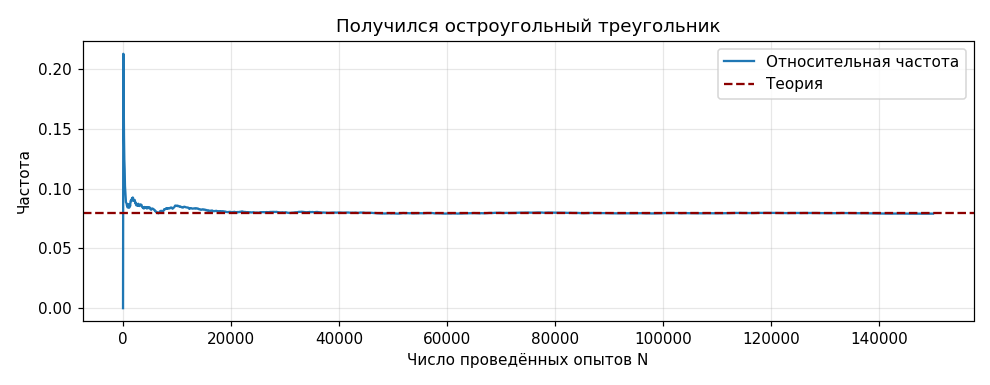

Частота существования треугольника: 0.25015333333333334 ; теория 0.25
Остроугольность при условии существования треугольника: успехов 11878, знаменатель 37523
  частота = 0.31655251; ориентир 95%: [0.31184618; 0.32125885]
  теория = 0.31776617; разность = -0.00121365


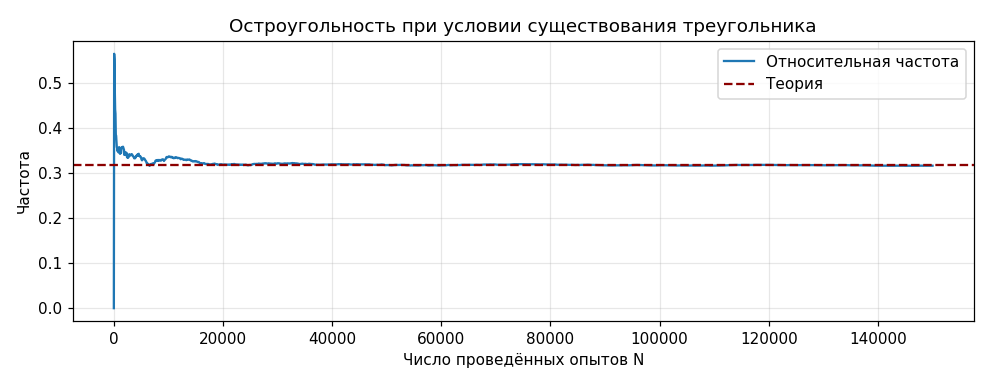

In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

N = 150_000
cuts = np.sort(rng.random((N, 2)), axis=1)
a = cuts[:, 0]
b = cuts[:, 1]-cuts[:, 0]
c = 1-cuts[:, 1]
sides = np.sort(np.column_stack((a, b, c)), axis=1)
triangle = sides[:, 2] < sides[:, 0]+sides[:, 1]
acute = sides[:, 2]**2 < sides[:, 0]**2+sides[:, 1]**2
A = triangle & acute
exact = 3*math.log(2)-2
report(A, 'Получился остроугольный треугольник', exact)
print('Частота существования треугольника:', np.mean(triangle), '; теория 0.25')
report(A, 'Остроугольность при условии существования треугольника', 4*exact, triangle)
